In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import torch
import torch.nn as nn
from sklearn import datasets
import matplotlib.pyplot as plt

1) Design Model (input, output size, forward pass)
2) Construct loss and optimizer
3) Training loop
	- forward pass: compute prediction
	- backward pass: gradients
	- update weights


In [3]:
# 0) prepare data

X_numpy, y_numpy = datasets.make_regression(n_samples=100, n_features=1, noise=20, random_state=1903)

X = torch.from_numpy(X_numpy.astype(np.float32))
y = torch.from_numpy(y_numpy.astype(np.float32))

y = y.view(y.shape[0], 1)

n_samples, n_features = X.shape

In [4]:
# 1)model
# 2)loss and optimizer
# 3)training loop

In [5]:
# 1) model
input_size = n_features
output_size = 1
model = nn.Linear(input_size, output_size)

In [6]:
# 2) loss and optimizer
learning_rate = 0.01
criteiron = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

In [7]:
# 3) trainig loop
n_epochs = 410
for epoch in range(n_epochs):
    # forward pass and loss
    y_pred = model(X)
    loss = criteiron(y_pred, y)
    
    # backward pass
    loss.backward()

    # update
    optimizer.step()

    optimizer.zero_grad() # bu satır önemli backward yapınca .grad a koyuyoruz değerleri eğer sıfırlamazsak öncekilerle bilrikte işleme giriyor
    if (epoch % 10 == 0 ):
        print(f"epoch {epoch+1}: loss = {loss.item():.4f}")

epoch 1: loss = 832.1012
epoch 11: loss = 677.6450
epoch 21: loss = 573.7928
epoch 31: loss = 503.9647
epoch 41: loss = 457.0131
epoch 51: loss = 425.4428
epoch 61: loss = 404.2149
epoch 71: loss = 389.9410
epoch 81: loss = 380.3430
epoch 91: loss = 373.8891
epoch 101: loss = 369.5492
epoch 111: loss = 366.6309
epoch 121: loss = 364.6684
epoch 131: loss = 363.3488
epoch 141: loss = 362.4614
epoch 151: loss = 361.8647
epoch 161: loss = 361.4633
epoch 171: loss = 361.1935
epoch 181: loss = 361.0120
epoch 191: loss = 360.8899
epoch 201: loss = 360.8078
epoch 211: loss = 360.7527
epoch 221: loss = 360.7155
epoch 231: loss = 360.6906
epoch 241: loss = 360.6737
epoch 251: loss = 360.6625
epoch 261: loss = 360.6549
epoch 271: loss = 360.6498
epoch 281: loss = 360.6463
epoch 291: loss = 360.6440
epoch 301: loss = 360.6425
epoch 311: loss = 360.6414
epoch 321: loss = 360.6407
epoch 331: loss = 360.6402
epoch 341: loss = 360.6399
epoch 351: loss = 360.6397
epoch 361: loss = 360.6396
epoch 371: l

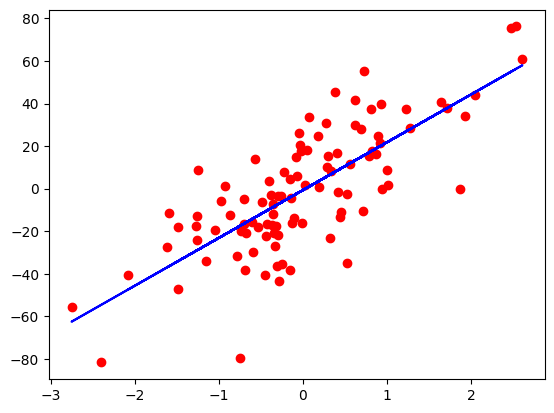

In [8]:
# plot

predicted = model(X).detach().numpy()
plt.plot(X_numpy, y_numpy, 'ro')
plt.plot(X_numpy, predicted, 'b')
plt.show()